<a href="https://colab.research.google.com/github/IvanRUDN/IST2026_autumn/blob/main/Lab3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №3
## Методы оптимизации в машинном обучении

 градиентный спуск, метод Ньютона и логистическая регрессия с L2-регуляризацией.



In [27]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, '/content/data')

import optimization
import oracles
from plot_trajectory_2d import plot_levels, plot_trajectory

np.random.seed(42)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

print("Библиотеки загружены")


Библиотеки загружены


##  Проверка квадратичного оракула



In [28]:
A = np.array([[4.0, 1.0], [1.0, 2.0]])
b = np.array([1.0, 1.0])
oracle = oracles.QuadraticOracle(A, b)

x = np.array([0.0, 0.0])
print("Значение функции:", oracle.func(x))
print("Градиент:", oracle.grad(x))
print("Матрица Гессе:")
print(oracle.hess(x))

x_exact = np.linalg.solve(A, b)
print("Точка минимума по формуле:", x_exact)


Значение функции: 0.0
Градиент: [-1. -1.]
Матрица Гессе:
[[4. 1.]
 [1. 2.]]
Точка минимума по формуле: [0.14285714 0.42857143]


##  Численная оценка градиента и матрицы Гессе



In [29]:
def test_func(x):
    return x[0] ** 3 + x[1] ** 2

point = np.array([2.0, 3.0])
grad_num = oracles.grad_finite_diff(test_func, point)
hess_num = oracles.hess_finite_diff(test_func, point)

grad_exact = np.array([3 * point[0] ** 2, 2 * point[1]])
hess_exact = np.array([[6 * point[0], 0.0], [0.0, 2.0]])

print("Численный градиент:", grad_num)
print("Точный градиент:", grad_exact)
print("Погрешность градиента:", np.linalg.norm(grad_num - grad_exact))
print("\nЧисленная матрица Гессе:\n", hess_num)
print("Точная матрица Гессе:\n", hess_exact)
print("Погрешность Гессиана:", np.linalg.norm(hess_num - hess_exact))


Численный градиент: [12.  6.]
Точный градиент: [12.  6.]
Погрешность градиента: 1.8753182155269257e-09

Численная матрица Гессе:
 [[1.19999992e+01 4.44089210e-07]
 [4.44089210e-07 1.99999839e+00]]
Точная матрица Гессе:
 [[12.  0.]
 [ 0.  2.]]
Погрешность Гессиана: 1.8982047401762488e-06


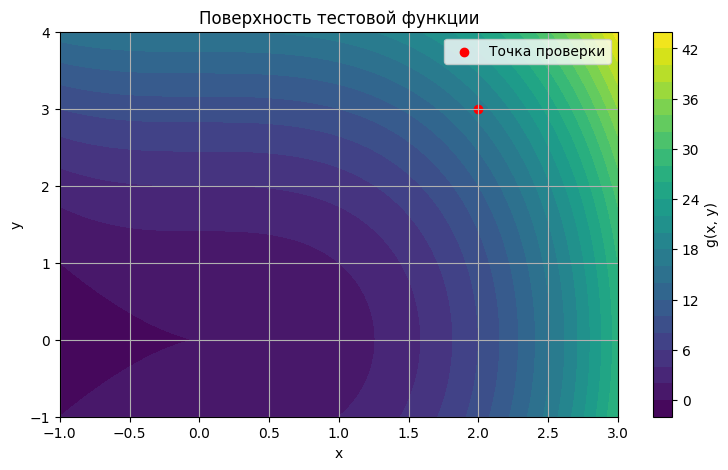

In [30]:
# График функции для наглядности
xx = np.linspace(-1, 3, 120)
yy = np.linspace(-1, 4, 120)
XX, YY = np.meshgrid(xx, yy)
ZZ = XX**3 + YY**2

plt.figure()
cont = plt.contourf(XX, YY, ZZ, levels=25)
plt.colorbar(cont, label="g(x, y)")
plt.scatter(point[0], point[1], color="red", label="Точка проверки")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Поверхность тестовой функции")
plt.legend()
plt.show()


##  Градиентный спуск



In [31]:
A_slow = np.array([[1.0, 0.0], [0.0, 30.0]])
b_slow = np.array([1.0, 1.0])
oracle_slow = oracles.QuadraticOracle(A_slow, b_slow)
x0 = np.array([8.0, 8.0])

x_star_slow = np.linalg.solve(A_slow, b_slow)
L = np.linalg.eigvalsh(A_slow).max()
step = 1.0 / L

x_gd, message_gd, history_gd = optimization.gradient_descent(
    oracle_slow, x0, tolerance=1e-12, max_iter=2500,
    line_search_options={"method": "Constant", "c": step},
    trace=True
)

print("Результат:", x_gd)
print("Статус:", message_gd)
print("Значение функции:", oracle_slow.func(x_gd))
print("Количество итераций:", len(history_gd["func"]) - 1)


Результат: [1.         0.03333333]
Статус: success
Значение функции: -0.5166666666666667
Количество итераций: 873


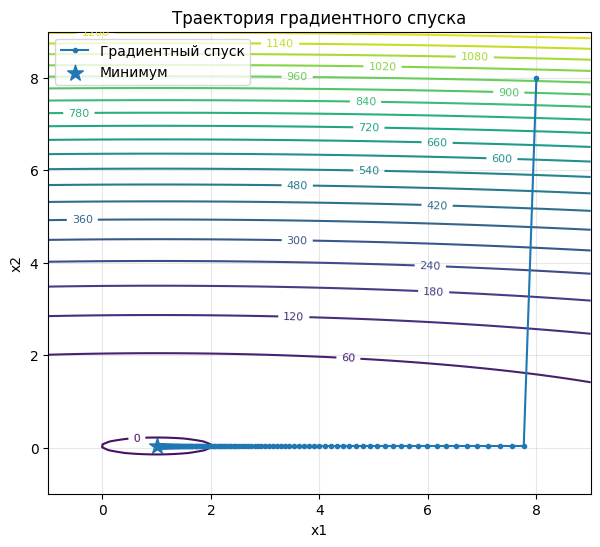

In [32]:
plt.figure(figsize=(7, 6))
plot_levels(oracle_slow.func, xrange=[-1, 9], yrange=[-1, 9], levels=22)
plot_trajectory(oracle_slow.func, history_gd["x"], label="Градиентный спуск")
plt.scatter([x_star_slow[0]], [x_star_slow[1]], marker="*", s=140, label="Минимум")
plt.title("Траектория градиентного спуска")
plt.legend()
plt.show()


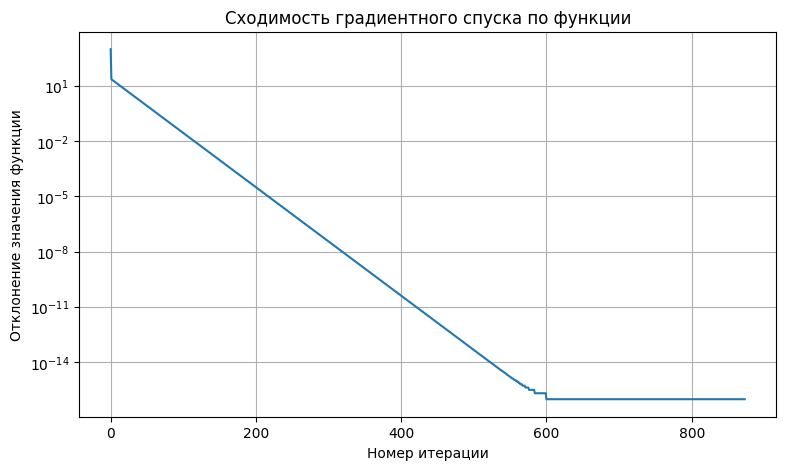

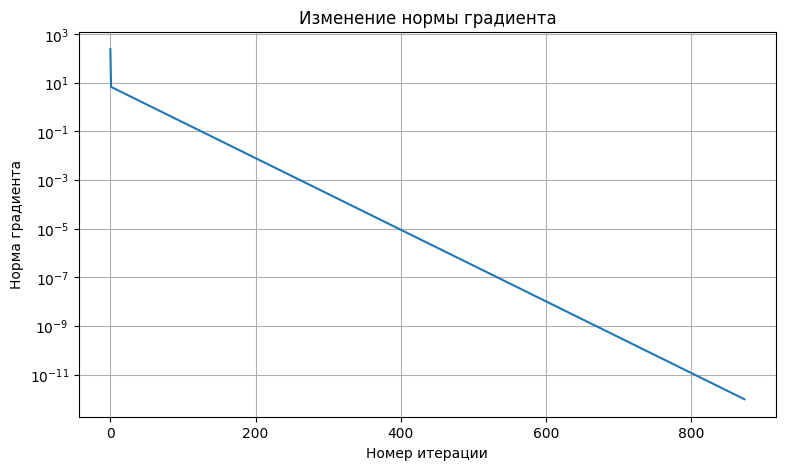

In [33]:
plt.figure()
plt.semilogy(np.array(history_gd["func"]) - oracle_slow.func(x_star_slow) + 1e-16)
plt.xlabel("Номер итерации")
plt.ylabel("Отклонение значения функции")
plt.title("Сходимость градиентного спуска по функции")
plt.show()

plt.figure()
plt.semilogy(history_gd["grad_norm"])
plt.xlabel("Номер итерации")
plt.ylabel("Норма градиента")
plt.title("Изменение нормы градиента")
plt.show()


##  Метод Ньютона



In [34]:
x_newton, message_newton, history_newton = optimization.newton(
    oracle_slow, x0, tolerance=1e-10, max_iter=100,
    line_search_options={"method": "Constant", "c": 1.0},
    trace=True
)

print("Результат:", x_newton)
print("Статус:", message_newton)
print("Значение функции:", oracle_slow.func(x_newton))
print("Количество итераций:", len(history_newton["func"]) - 1)


Результат: [1.         0.03333333]
Статус: success
Значение функции: -0.5166666666666667
Количество итераций: 1


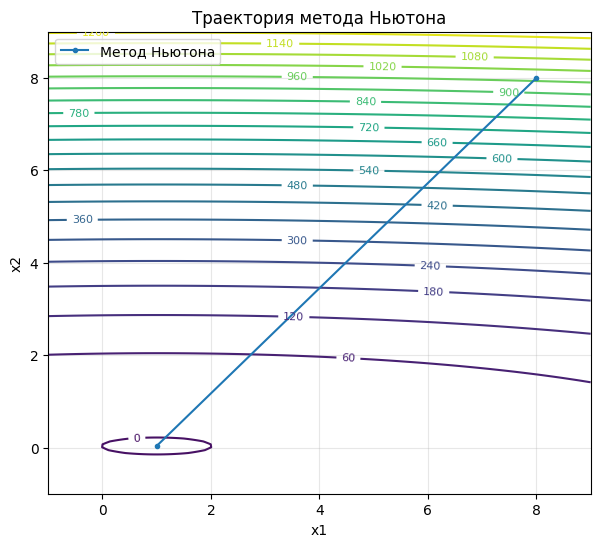

In [35]:
plt.figure(figsize=(7, 6))
plot_levels(oracle_slow.func, xrange=[-1, 9], yrange=[-1, 9], levels=22)
plot_trajectory(oracle_slow.func, history_newton["x"], label="Метод Ньютона")
plt.title("Траектория метода Ньютона")
plt.legend()
plt.show()


##  Сравнение методов



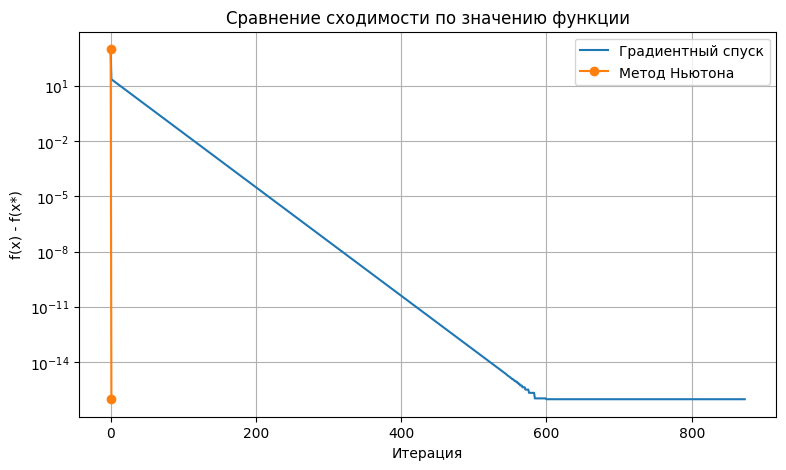

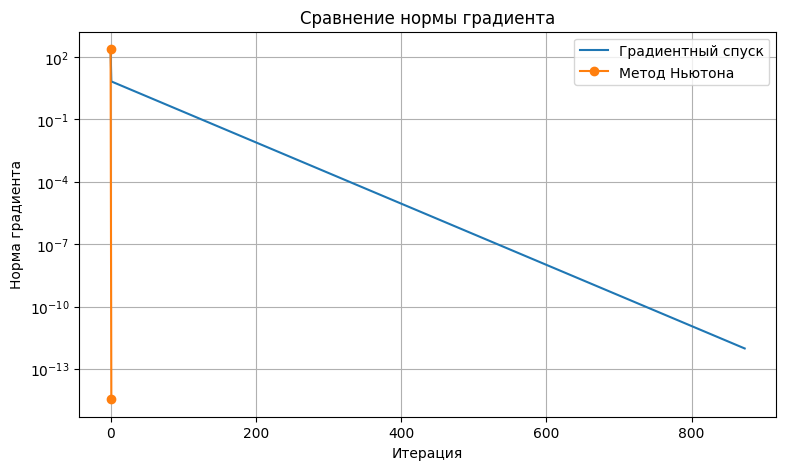

In [36]:
gd_iter = np.arange(len(history_gd["func"]))
newton_iter = np.arange(len(history_newton["func"]))

plt.figure()
plt.semilogy(gd_iter, np.maximum(np.array(history_gd["func"]) - oracle_slow.func(x_star_slow), 1e-16),
             label="Градиентный спуск")
plt.semilogy(newton_iter, np.maximum(np.array(history_newton["func"]) - oracle_slow.func(x_star_slow), 1e-16),
             marker="o", label="Метод Ньютона")
plt.xlabel("Итерация")
plt.ylabel("f(x) - f(x*)")
plt.title("Сравнение сходимости по значению функции")
plt.legend()
plt.show()

plt.figure()
plt.semilogy(history_gd["grad_norm"], label="Градиентный спуск")
plt.semilogy(history_newton["grad_norm"], marker="o", label="Метод Ньютона")
plt.xlabel("Итерация")
plt.ylabel("Норма градиента")
plt.title("Сравнение нормы градиента")
plt.legend()
plt.show()


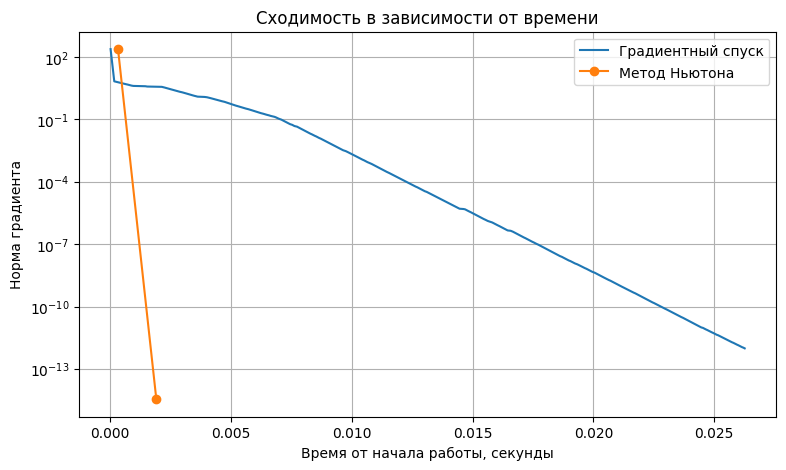

,Метод,Итерации,Итоговая функция,Итоговая норма градиента,"Время, сек"
0,Градиентный спуск,873,-0.516667,9.809931e-13,0.026262
1,Метод Ньютона,1,-0.516667,3.552714e-15,0.001907


In [37]:
plt.figure()
plt.plot(history_gd["time"], history_gd["grad_norm"], label="Градиентный спуск")
plt.plot(history_newton["time"], history_newton["grad_norm"], marker="o", label="Метод Ньютона")
plt.yscale("log")
plt.xlabel("Время от начала работы, секунды")
plt.ylabel("Норма градиента")
plt.title("Сходимость в зависимости от времени")
plt.legend()
plt.show()

comparison = pd.DataFrame({
    "Метод": ["Градиентный спуск", "Метод Ньютона"],
    "Итерации": [len(history_gd["func"]) - 1, len(history_newton["func"]) - 1],
    "Итоговая функция": [oracle_slow.func(x_gd), oracle_slow.func(x_newton)],
    "Итоговая норма градиента": [history_gd["grad_norm"][-1], history_newton["grad_norm"][-1]],
    "Время, сек": [history_gd["time"][-1], history_newton["time"][-1]]
})
comparison


##  Логистическая регрессия с L2-регуляризацией



In [38]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

X, y = make_classification(
    n_samples=900, n_features=18, n_informative=12,
    n_redundant=3, class_sep=1.1, random_state=42
)
y = np.where(y == 1, 1, -1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

logreg = oracles.LogRegL2Oracle(X_train, y_train, regcoef=1e-2)
x_start = np.zeros(X_train.shape[1])

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Начальное значение функции:", logreg.func(x_start))


Размер обучающей выборки: (675, 18)
Размер тестовой выборки: (225, 18)
Начальное значение функции: 0.6931471805599453


In [39]:
# Проверим градиент на нескольких координатах
g_analytical = logreg.grad(x_start)
g_numeric = oracles.grad_finite_diff(logreg.func, x_start)
print("Разница аналитического и численного градиента:",
      np.linalg.norm(g_analytical - g_numeric))


Разница аналитического и численного градиента: 1.293227323028789e-10


###  Обучение градиентным спуском


In [40]:
start_time = time.perf_counter()
w_gd, status_log_gd, hist_log_gd = optimization.gradient_descent(
    logreg, x_start, tolerance=1e-6, max_iter=1800,
    line_search_options={"method": "Wolfe", "alpha_0": 1.0},
    trace=True
)
gd_wall_time = time.perf_counter() - start_time

pred_gd = np.where(X_test @ w_gd >= 0, 1, -1)
acc_gd = accuracy_score(y_test, pred_gd)

print("Статус:", status_log_gd)
print("Итераций:", len(hist_log_gd["func"]) - 1)
print("Финальная функция:", logreg.func(w_gd))
print("Точность на тесте:", round(acc_gd, 4))
print("Время выполнения, сек:", round(gd_wall_time, 4))


Статус: success
Итераций: 198
Финальная функция: 0.39010033702505276
Точность на тесте: 0.8133
Время выполнения, сек: 0.159


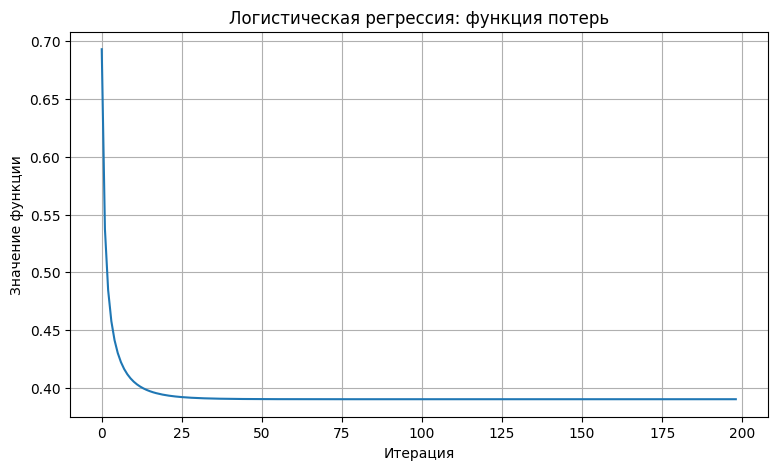

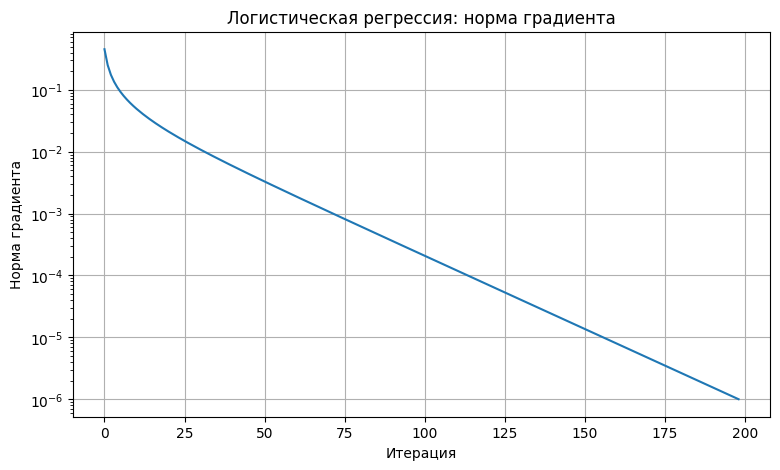

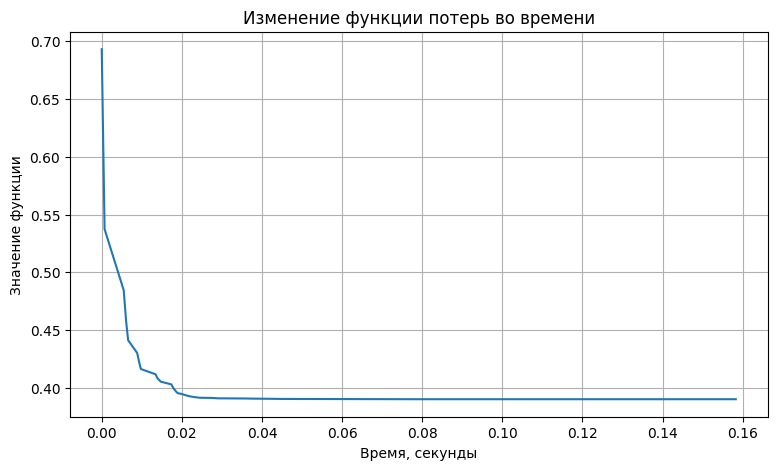

In [41]:
plt.figure()
plt.plot(hist_log_gd["func"])
plt.xlabel("Итерация")
plt.ylabel("Значение функции")
plt.title("Логистическая регрессия: функция потерь")
plt.show()

plt.figure()
plt.semilogy(hist_log_gd["grad_norm"])
plt.xlabel("Итерация")
plt.ylabel("Норма градиента")
plt.title("Логистическая регрессия: норма градиента")
plt.show()

plt.figure()
plt.plot(hist_log_gd["time"], hist_log_gd["func"])
plt.xlabel("Время, секунды")
plt.ylabel("Значение функции")
plt.title("Изменение функции потерь во времени")
plt.show()


###  Обучение методом Ньютона



In [42]:
start_time = time.perf_counter()
w_newton, status_log_newton, hist_log_newton = optimization.newton(
    logreg, x_start, tolerance=1e-6, max_iter=80,
    line_search_options={"method": "Wolfe", "alpha_0": 1.0},
    trace=True
)
newton_wall_time = time.perf_counter() - start_time

pred_newton = np.where(X_test @ w_newton >= 0, 1, -1)
acc_newton = accuracy_score(y_test, pred_newton)

print("Статус:", status_log_newton)
print("Итераций:", len(hist_log_newton["func"]) - 1)
print("Финальная функция:", logreg.func(w_newton))
print("Точность на тесте:", round(acc_newton, 4))
print("Время выполнения, сек:", round(newton_wall_time, 4))


Статус: success
Итераций: 5
Финальная функция: 0.3901003370156219
Точность на тесте: 0.8133
Время выполнения, сек: 0.0077


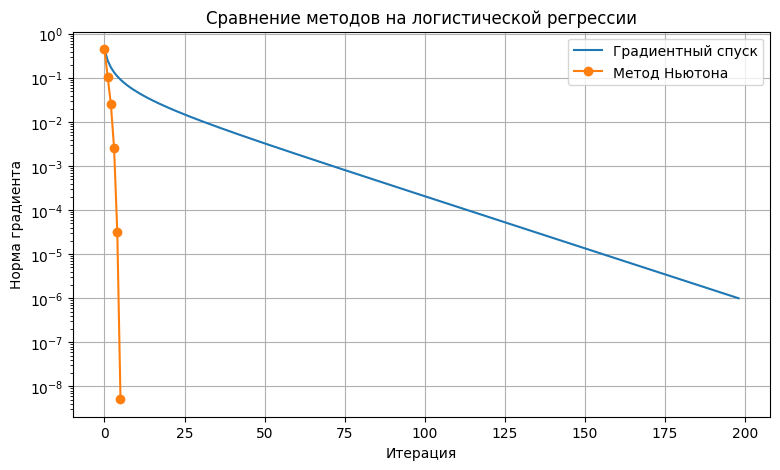

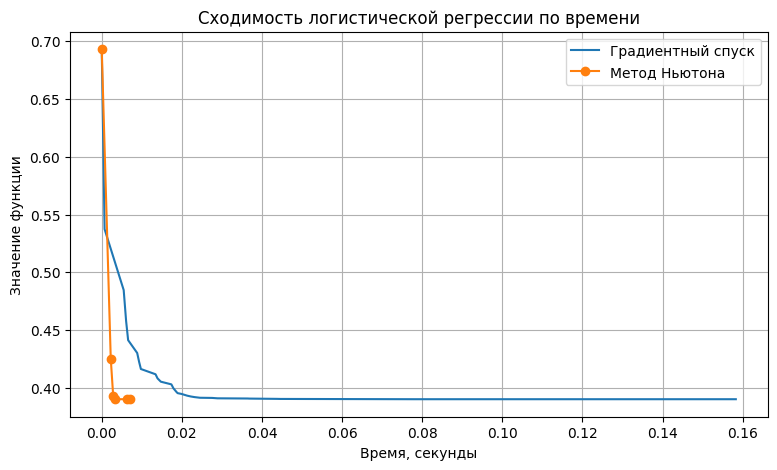

In [43]:
plt.figure()
plt.semilogy(hist_log_gd["grad_norm"], label="Градиентный спуск")
plt.semilogy(hist_log_newton["grad_norm"], marker="o", label="Метод Ньютона")
plt.xlabel("Итерация")
plt.ylabel("Норма градиента")
plt.title("Сравнение методов на логистической регрессии")
plt.legend()
plt.show()

plt.figure()
plt.plot(hist_log_gd["time"], hist_log_gd["func"], label="Градиентный спуск")
plt.plot(hist_log_newton["time"], hist_log_newton["func"], marker="o", label="Метод Ньютона")
plt.xlabel("Время, секунды")
plt.ylabel("Значение функции")
plt.title("Сходимость логистической регрессии по времени")
plt.legend()
plt.show()


In [44]:
logreg_comparison = pd.DataFrame({
    "Метод": ["Градиентный спуск", "Метод Ньютона"],
    "Итерации": [len(hist_log_gd["func"]) - 1, len(hist_log_newton["func"]) - 1],
    "Функция потерь": [logreg.func(w_gd), logreg.func(w_newton)],
    "Точность на тесте": [acc_gd, acc_newton],
    "Время, сек": [gd_wall_time, newton_wall_time]
})
logreg_comparison


,Метод,Итерации,Функция потерь,Точность на тесте,"Время, сек"
0,Градиентный спуск,198,0.3901,0.813333,0.158989
1,Метод Ньютона,5,0.3901,0.813333,0.007714


##  Дополнительный эксперимент: влияние числа итераций



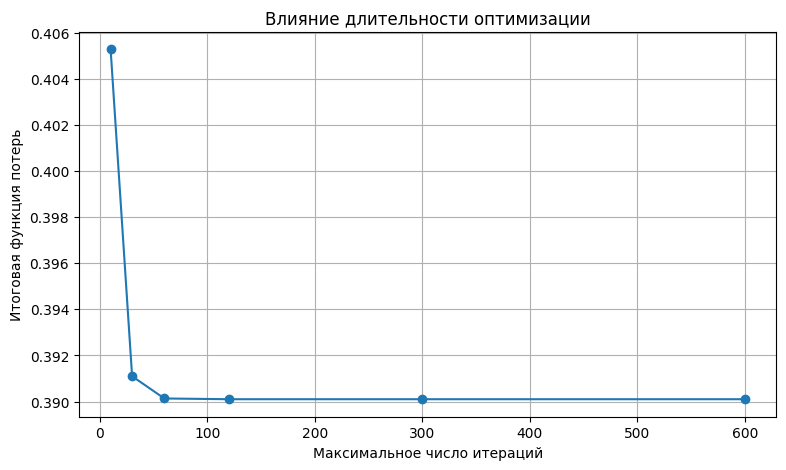

,Итерации,Функция потерь
0,10,0.405277
1,30,0.391097
2,60,0.390133
3,120,0.390100
4,300,0.390100
5,600,0.390100


In [45]:
iteration_limits = [10, 30, 60, 120, 300, 600]
loss_by_limit = []
for limit in iteration_limits:
    w_tmp, status_tmp, hist_tmp = optimization.gradient_descent(
        logreg, x_start, tolerance=0.0, max_iter=limit,
        line_search_options={"method": "Wolfe"}, trace=True
    )
    loss_by_limit.append(logreg.func(w_tmp))

plt.figure()
plt.plot(iteration_limits, loss_by_limit, marker="o")
plt.xlabel("Максимальное число итераций")
plt.ylabel("Итоговая функция потерь")
plt.title("Влияние длительности оптимизации")
plt.show()

pd.DataFrame({"Итерации": iteration_limits, "Функция потерь": loss_by_limit})


##  Использование реальных датасетов

In [49]:
from pathlib import Path
from sklearn.datasets import load_svmlight_file

data_dir = Path("data")

files = ["w8a.txt", "gisette_scale", "real-sim"]

for filename in files:
    path = data_dir / filename

    if not path.exists():
        print("Файл не найден:", path)
        continue

    try:
        print("\nОбрабатывается файл:", filename)

        A_data, b_data = load_svmlight_file(str(path))

        # Для ускорения используем не более 5000 объектов
        A_data = A_data[:5000]
        b_data = b_data[:5000]

        b_data = np.where(b_data > 0, 1, -1)

        real_oracle = oracles.LogRegL2Oracle(
            A_data, b_data, regcoef=1e-3
        )

        result, status, hist = optimization.gradient_descent(
            real_oracle,
            np.zeros(A_data.shape[1]),
            tolerance=1e-4,
            max_iter=50,
            line_search_options={"method": "Wolfe"},
            trace=True
        )

        print("Статус:", status)
        print("Количество итераций:", len(hist["func"]) - 1)
        print("Значение функции:", round(real_oracle.func(result), 6))

    except Exception as e:
        print("Ошибка", filename, ":", e)




Обрабатывается файл: w8a.txt
Статус: iterations_exceeded
Количество итераций: 50
Значение функции: 0.373624

Обрабатывается файл: gisette_scale
Статус: iterations_exceeded
Количество итераций: 50
Значение функции: 0.19106

Обрабатывается файл: real-sim
Статус: iterations_exceeded
Количество итераций: 50
Значение функции: 0.554744


##  Вывод

В лабораторной работе были реализованы оракулы квадратичной функции и логистической регрессии с L2-регуляризацией. Также были реализованы численные оценки градиента и матрицы Гессе, градиентный спуск, метод Ньютона и поиск шага.

